In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel('Sample_Superstore_Cleaned.xlsx')
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Month'] = df['Order Date'].dt.to_period('M')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Month
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,2023-01
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,2023-01
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717,2023-01
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,2023-01
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,2023-01


In [2]:
monthly = df.groupby('Month').agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Orders=('Order ID', 'nunique')
).reset_index()
monthly['Month Start'] = monthly['Month'].dt.to_timestamp()

# Growth compared with previous month and same month last year
monthly['MoM Sales Growth (%)'] = monthly['Sales'].pct_change() * 100
monthly['YoY Sales Growth (%)'] = monthly['Sales'].pct_change(12) * 100

# Profit growth only when the comparison-period profit is positive
monthly['MoM Profit Growth (%)'] = monthly['Profit'].pct_change() * 100
monthly.loc[monthly['Profit'].shift(1) <= 0, 'MoM Profit Growth (%)'] = None
monthly['YoY Profit Growth (%)'] = monthly['Profit'].pct_change(12) * 100
monthly.loc[monthly['Profit'].shift(12) <= 0, 'YoY Profit Growth (%)'] = None

monthly.round(2).tail(15)

,Month,Sales,Profit,Orders,Month Start,MoM Sales Growth (%),YoY Sales Growth (%),MoM Profit Growth (%),YoY Profit Growth (%)
33,2025-10,59831.00,16256.84,107,2025-10-01,-18.62,90.50,73.50,476.90
34,2025-11,79411.97,4011.41,183,2025-11-01,32.73,4.53,-75.32,-67.84
35,2025-12,97502.28,17926.30,185,2025-12-01,22.78,29.09,346.88,121.50
36,2026-01,44259.21,7231.64,71,2026-01-01,-54.61,135.04,-59.66,148.00
37,2026-02,20301.13,1613.87,53,2026-02-01,-54.13,-11.65,-77.68,-67.75
38,2026-03,60728.48,15013.09,121,2026-03-01,199.14,14.51,830.25,304.90
39,2026-04,36779.04,957.53,117,2026-04-01,-39.44,-5.28,-93.62,-67.99
40,2026-05,45155.48,6299.81,121,2026-05-01,22.78,-20.84,557.92,-27.39
41,2026-06,53056.08,8246.57,134,2026-06-01,17.50,29.60,30.90,67.40
42,2026-07,45989.50,7006.50,112,2026-07-01,-13.32,14.12,-15.04,53.66


In [3]:
print('Total sales:', round(df['Sales'].sum(), 2))
print('Total profit:', round(df['Profit'].sum(), 2))
print('Distinct orders:', df['Order ID'].nunique())
print('Months:', len(monthly))
print('Average comparable monthly sales growth:', round(monthly['YoY Sales Growth (%)'].mean(), 2), '%')

Total sales: 2326534.35
Total profit: 292296.81
Distinct orders: 5111
Months: 48
Average comparable monthly sales growth: 26.93 %


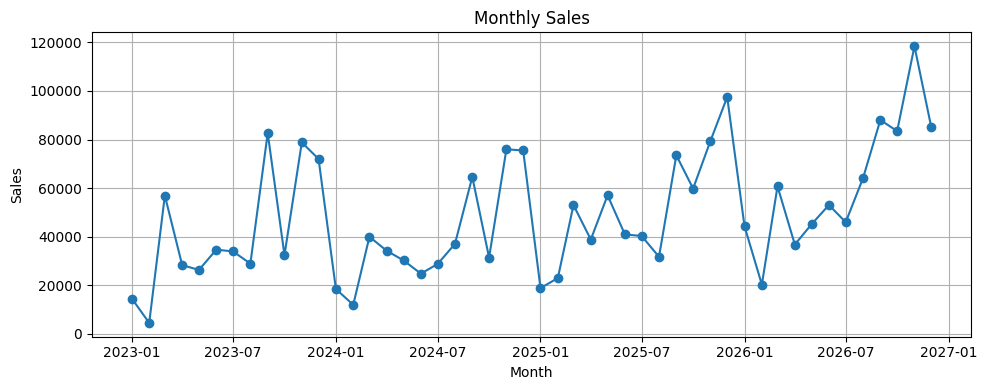

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(monthly['Month Start'], monthly['Sales'], marker='o')
plt.title('Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.grid(True)
plt.tight_layout()
plt.show()

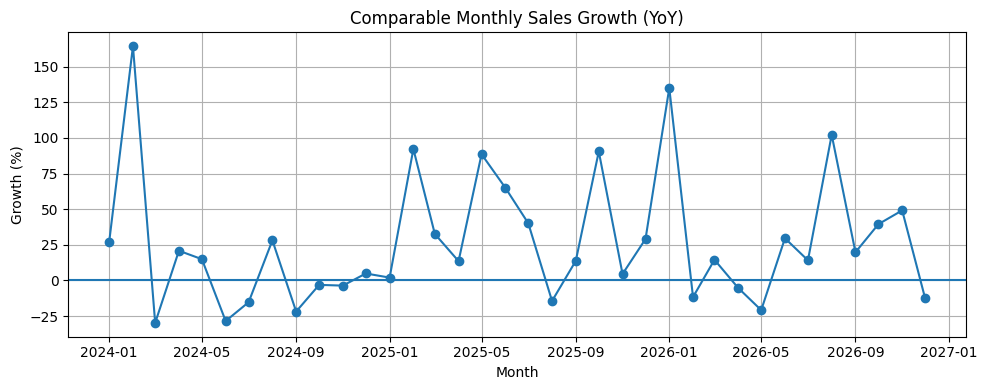

In [5]:
plt.figure(figsize=(10, 4))
plt.axhline(0)
plt.plot(monthly['Month Start'], monthly['YoY Sales Growth (%)'], marker='o')
plt.title('Comparable Monthly Sales Growth (YoY)')
plt.xlabel('Month')
plt.ylabel('Growth (%)')
plt.grid(True)
plt.tight_layout()
plt.show()

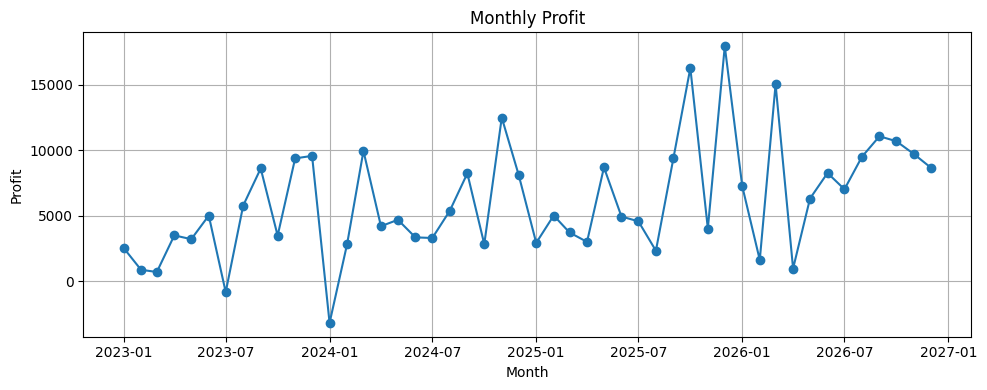

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(monthly['Month Start'], monthly['Profit'], marker='o')
plt.title('Monthly Profit')
plt.xlabel('Month')
plt.ylabel('Profit')
plt.grid(True)
plt.tight_layout()
plt.show()